# Compare OTUs: body size and locomotion
Run all cells from top to bottom. Data are loaded once (first section), and every later section uses only what is built there.
Settings that change what is plotted are all in the second cell.

In [1]:
import os
import glob
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats
import scikit_posthocs as sp
import statsmodels.api as sm
import statsmodels.formula.api as smf
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

print('scikit_posthocs', sp.__version__)
print('statsmodels', sm.__version__)

scikit_posthocs 0.16.1
statsmodels 0.14.6


In [2]:
# settings
included = 'sequenced'   # 'sequenced' or 'all': which individuals to show in the plots
bl_threshold = 2         # body lengths traveled to count as active ('mover')
min_num_for_movers = 10  # minimum number of active individuals for an OTU to be compared

# Load data

In [3]:
# OTU order and revised names come from Table 3; locomotion files use the submitted names
otu_table = pd.read_excel('Tables/Table 3.xlsx')
seq_otus_revised = otu_table['OTU'].values

otu_updated = pd.read_excel('otu_revision.xlsx')
otu_original_to_revised = dict(zip(otu_updated['OTU-submitted'], otu_updated['OTU-revised']))
otu_revised_to_original = dict(zip(otu_updated['OTU-revised'], otu_updated['OTU-submitted']))
seq_otus = [otu_revised_to_original[x] for x in seq_otus_revised] # submitted names, in Table 3 order

otu_plot_df = pd.read_excel('otu_colors.xlsx')
otu_colors = dict(zip(otu_plot_df['OTU'], otu_plot_df['color']))
otu_markers = dict(zip(otu_plot_df['OTU'], otu_plot_df['marker']))
otu_colors['Macrobiotus_a'] = '#04d8b2' # a bit lighter if both a and f are shown

In [4]:
# Load locomotion data for every OTU and partition it:
#   all tardigrades, sequenced tardigrades, all movers, sequenced movers
# movers = moved at least bl_threshold body lengths
sequenced_df = pd.read_excel('Tables/Supplemental Table 3.xlsx')
sequenced_individuals = set(sequenced_df['SeqID'])

all_tardigrades = {}
sequenced_tardigrades = {}
all_movers = {}
sequenced_movers = {}

print('otu #filmed #filmed with seqID')
for otu, otu_revised in zip(seq_otus, seq_otus_revised):
    combined_file = os.path.join('locomotion', otu + '_combined.xlsx')
    if not os.path.exists(combined_file):
        print(otu_revised, 0, 0)
        continue
    otu_df = pd.read_excel(combined_file).dropna(subset=['Identifier'])
    is_sequenced = otu_df['Identifier'].isin(sequenced_individuals)
    is_mover = otu_df['Bodylengths traveled'] >= bl_threshold

    all_tardigrades[otu] = otu_df
    sequenced_tardigrades[otu] = otu_df[is_sequenced]
    all_movers[otu] = otu_df[is_mover]
    sequenced_movers[otu] = otu_df[is_sequenced & is_mover]
    print(otu_revised, len(otu_df), is_sequenced.sum())

if included == 'all':
    df_dict = all_tardigrades
    mover_df_dict = all_movers
else:
    df_dict = sequenced_tardigrades
    mover_df_dict = sequenced_movers

otu #filmed #filmed with seqID
Pseudechiniscus sp. a 29 16
Viridiscus sp. a 6 4
Viridiscus sp. a3 0 0
Echiniscus sp. b 14 10
Milnesium sp. a 36 17
Ramazzottius sp. a 6 5
Ramazzottius sp. b 8 7
Ramazzottius sp. b1 24 18
Ursulinius sp. a 1 1
Isohypsibius sp. a 13 11
Isohypsibius sp. a2 10 7
Isohypsibiidae sp. a11 6 6
Adropion sp. a 3 3
Diphascon sp. a 16 14
Hypsibius sp. a 0 0
Hypsibius sp. b 7 2
Hypsibius sp. c 10 9
Hypsibius sp. d 3 2
Mesobiotus sp. a 7 5
Mesobiotus sp. a1 3 3
Minibiotus sp. a 54 43
Paramacrobiotus sp. a 32 25
Paramacrobiotus sp. b 10 9
Macrobiotus sp. a 18 17
Macrobiotus sp. b 1 1
Macrobiotus sp. c 10 7
Macrobiotus sp. d 5 5
Macrobiotus sp. e 4 4
Macrobiotus sp. f 26 22
Macrobiotus sp. f1 6 4
Macrobiotus sp. g 2 2


In [5]:
def compplot(data, colname, figsize=(15,5), markersize=5, labelsize=16):
    f,ax = plt.subplots(1,1,figsize=figsize, dpi=150)
    otu_pal = {x: otu_colors[x] for x in data.keys()}
    sns.boxplot(data, showfliers=False, ax=ax, palette=otu_pal, width=0.9)
    sns.stripplot(data, color='k', ax=ax, jitter=0.2, size=markersize)
    ax.set_ylabel(colname, size=labelsize)
    ticks = ax.get_xticks()
    labels = [otu_original_to_revised[item.get_text()] for item in ax.get_xticklabels()]
    ax.tick_params(axis='x', labelrotation=90, labelsize=labelsize)
    ax.tick_params(axis='y', labelsize=labelsize)
    ax.set_xticks(ticks, labels=labels)
    ax.set_xlim([-0.6, len(data)-0.4])
    return f, ax

# Figure 3: body sizes, video counts, icons, and images

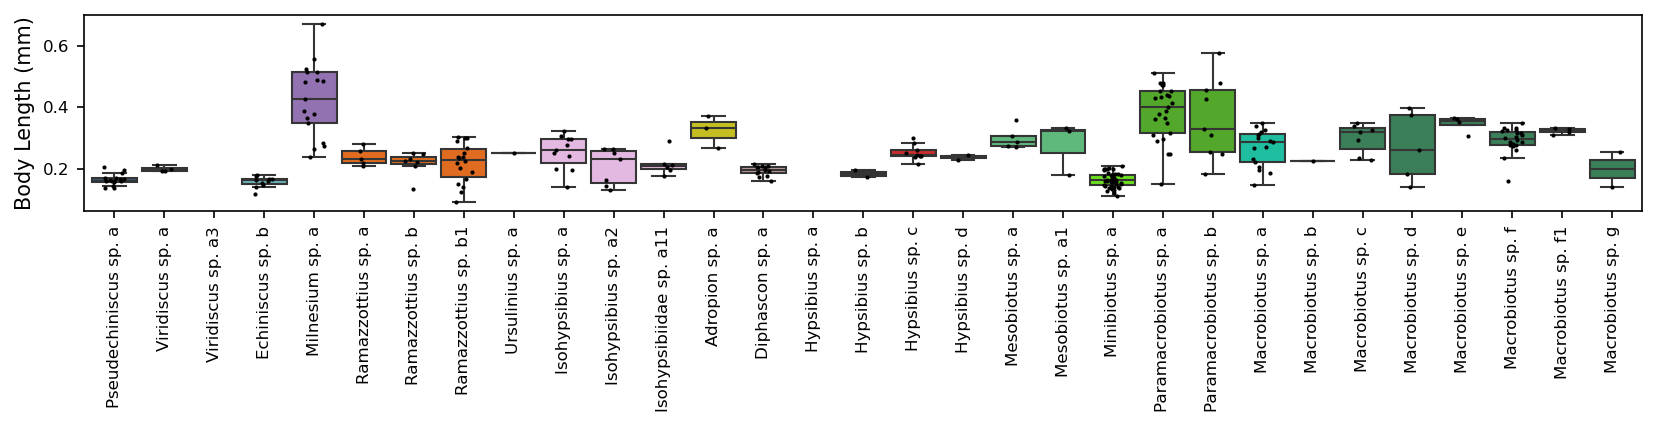

In [6]:
# body lengths for every OTU in Table 3 (OTUs without videos are shown as empty columns)
col = 'Body Length (mm)'
data = {otu: df_dict[otu][col].values if otu in df_dict else np.array([]) for otu in seq_otus}
vid_counts = {otu: len(data[otu]) for otu in seq_otus}

f, ax = compplot(data, col, figsize=(13.4,1.7), markersize=2)
ax.tick_params(axis='both', labelsize=8)
ax.yaxis.get_label().set_fontsize(10)
# option to put x tick labels on top
# ax.xaxis.tick_top()
plt.savefig('fig3 sizes ' + included + '.png', bbox_inches='tight', transparent=True, dpi=300)
plt.show()

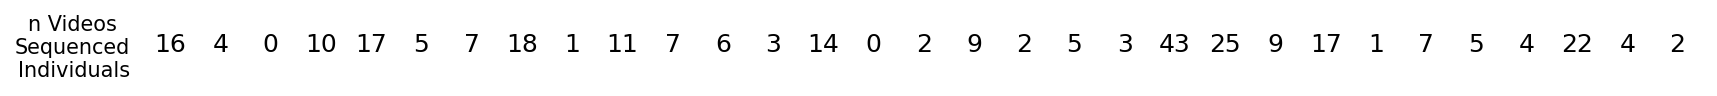

In [7]:
# number of videos for each OTU, as a strip to place under the size plot
f, ax = plt.subplots(1,1,figsize=(13.4, .4), dpi=150)
for i, otu in enumerate(seq_otus):
    ax.text(i, 1, s=str(vid_counts[otu]), ha='center', va='center', fontsize=12)
ax.set_xlim([-0.5, len(seq_otus)-0.5])
ax.set_ylim([0.8, 1.2])
ax.set_xticks([])
ax.tick_params(axis='y', left=False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_facecolor('none')
if included == 'sequenced':
    ax.set_yticks([1], ['n Videos  \nSequenced\nIndividuals'], fontsize=10)
else:
    ax.set_yticks([1], ['n Videos  '], fontsize=10)
plt.savefig('fig3_video_counts_' + included + '.png', bbox_inches='tight', transparent=True, dpi=300)
plt.show()

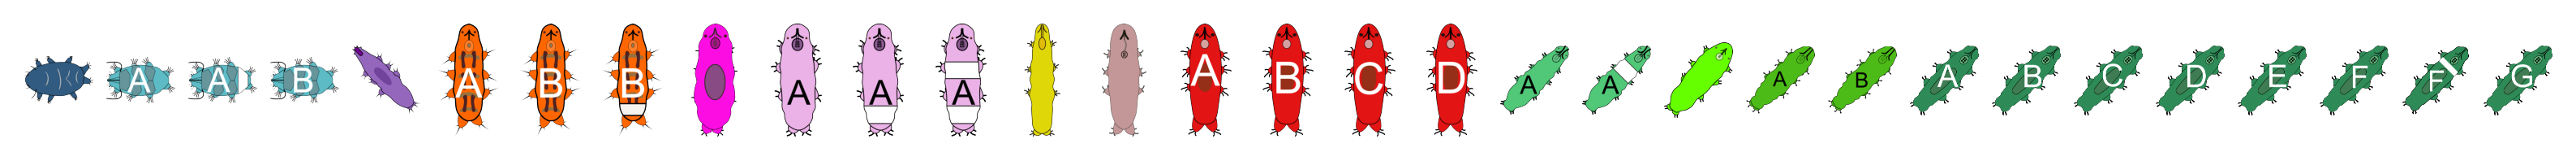

In [8]:
# map icons for each OTU
mapping_path = 'mapping/species_icons/0 pngs/'
fig, axes = plt.subplots(1, len(seq_otus), figsize=(13.4, .6), dpi=300)
for ax, otu in zip(axes, seq_otus):
    ax.imshow(Image.open(mapping_path + otu.lower() + '.png'))
    ax.set_axis_off()
# plt.savefig('fig3 map icon lineup.png', bbox_inches='tight', transparent=True)
plt.show()

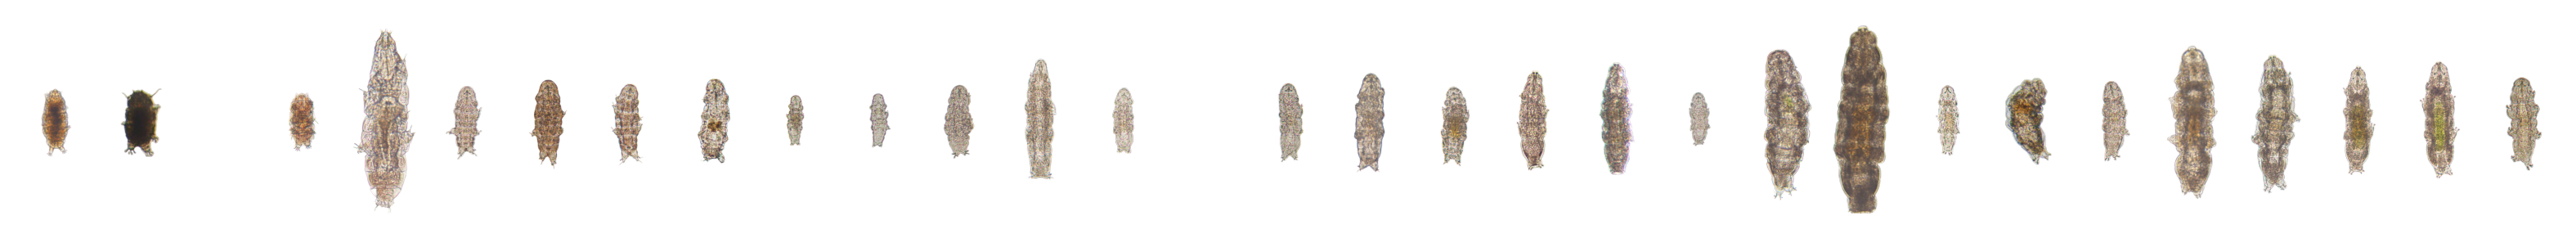

In [9]:
# tardigrade images all in a row pointing UP, cropped to the size of the largest tardigrade
img_folder = 'walking pics no background/'
walkers = glob.glob(img_folder + '*.png')
walker_files = {os.path.basename(w).split('.')[0].split()[0].lower(): w for w in walkers}

max_height = 1190 # longest tardigrade
max_width = 390 # widest tardigrade

f, axes = plt.subplots(1, len(seq_otus), figsize=(13.4,1), dpi=300)
for ax, otu in zip(axes, seq_otus):
    ax.set_axis_off()
    if otu.lower() not in walker_files:
        continue
    img = plt.imread(walker_files[otu.lower()])
    center_y = int(img.shape[0]/2)
    center_x = int(img.shape[1]/2)
    lower_x = int(center_x - max_width/2)
    upper_x = int(center_x + max_width/2)
    lower_y = int(center_y - max_height/2)
    upper_y = int(center_y + max_height/2)
    ax.imshow(img[lower_y:upper_y, lower_x:upper_x])
plt.subplots_adjust(wspace=0, hspace=0)
# plt.savefig('fig3 lineup.png', bbox_inches='tight')
plt.show()

# Figure 5A-B: speed and proportion of active tardigrades in each OTU

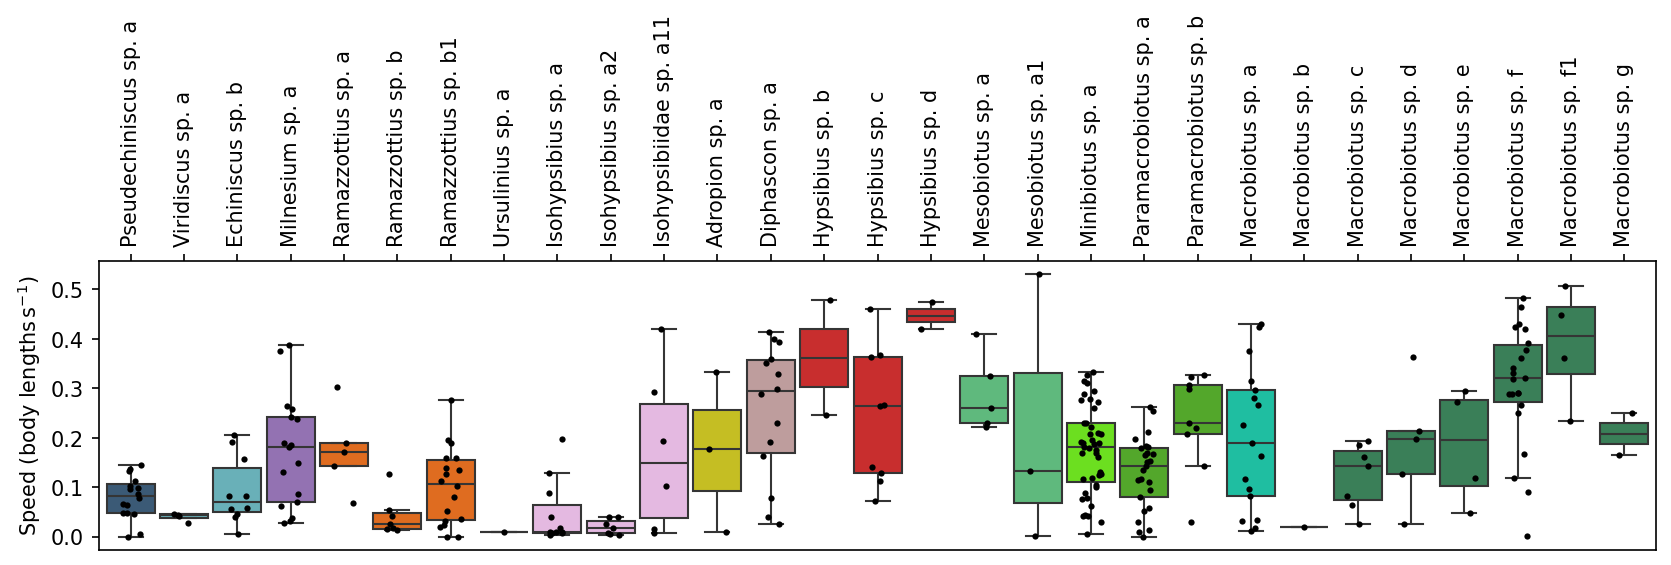

In [10]:
col = 'Speed (body lengths / sec)'
data = {otu: df_dict[otu][col].values for otu in seq_otus if otu in df_dict}

f, ax = compplot(data, col, figsize=(13.4,2.5), markersize=3, labelsize=10)
ax.xaxis.tick_top()
ax.set_ylabel(r"Speed (body lengths$\,$s$^{-1}$)")
plt.savefig('fig5_blspeed_' + included + '.png', bbox_inches='tight', transparent=True, dpi=300)
plt.show()

8 OTU groups where n >=10 moved a minimum of 2 body lengths
Pseudechiniscus_a
Milnesium_a
Ramazzottius_b1
Diphascon_a
Minibiotus_a
Paramacrobiotus_a
Macrobiotus_a
Macrobiotus_f


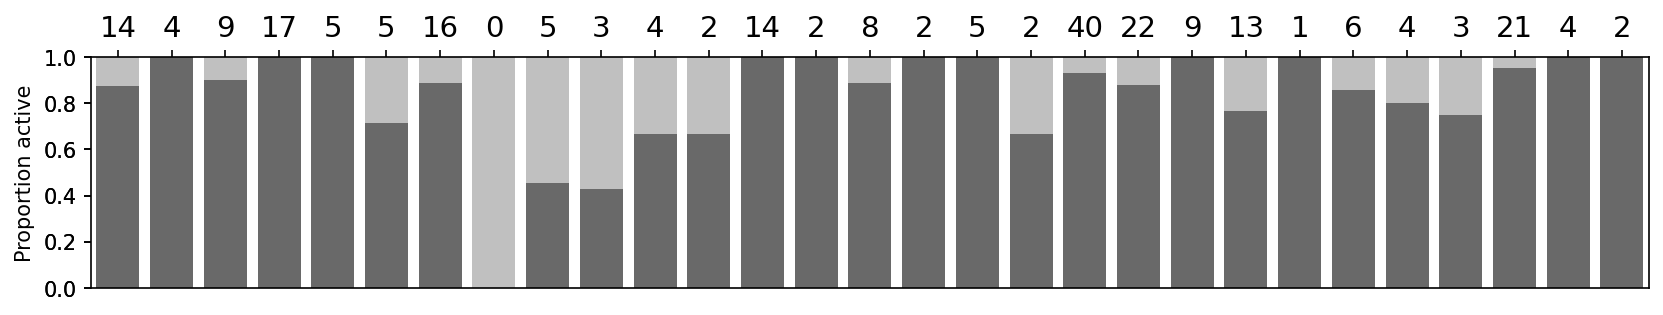

In [11]:
# proportion of movers in each OTU; OTUs with >= min_num_for_movers movers are compared below
included_in_plot = [otu for otu in seq_otus if otu in df_dict]
num_movers = [len(mover_df_dict[otu]) for otu in included_in_plot]
proportions = [len(mover_df_dict[otu]) / len(df_dict[otu]) for otu in included_in_plot]
included_in_movers = [otu for otu, n in zip(included_in_plot, num_movers) if n >= min_num_for_movers]

print(str(len(included_in_movers)) + ' OTU groups where n >=' + str(min_num_for_movers) + ' moved a minimum of ' + str(bl_threshold) + ' body lengths')
for otu in included_in_movers:
    print(otu)

f, ax = plt.subplots(1,1,figsize=(13.4,2), dpi=150)
for i, prop in enumerate(proportions):
    ax.bar(i, prop, color='dimgrey')
    ax.bar(i, 1-prop, bottom=prop, color='silver')
ax.set_xticks([])
ax.set_ylabel("Proportion active", fontsize=10)
ax.set_xlim([-0.5, len(included_in_plot) - 0.5])

upperax = f.add_subplot(111, frameon=False)
upperax.xaxis.tick_top()
upperax.set_xticks(np.arange(len(included_in_plot)), num_movers, fontsize=14)
upperax.set_xlim([-0.5, len(included_in_plot) - 0.5])

plt.savefig('fig5_mover_counts_' + included + '.png', bbox_inches='tight', transparent=True, dpi=300)
plt.show()

# Locomotion in movers (exploratory, not in the paper)
 * `Speed (body lengths / sec)` = clear differences between some groups, no outliers
 * `Percentage of time cruising` = broad range for all OTUs
 * `Bearing change (deg) / sec` = subtle differences between groups

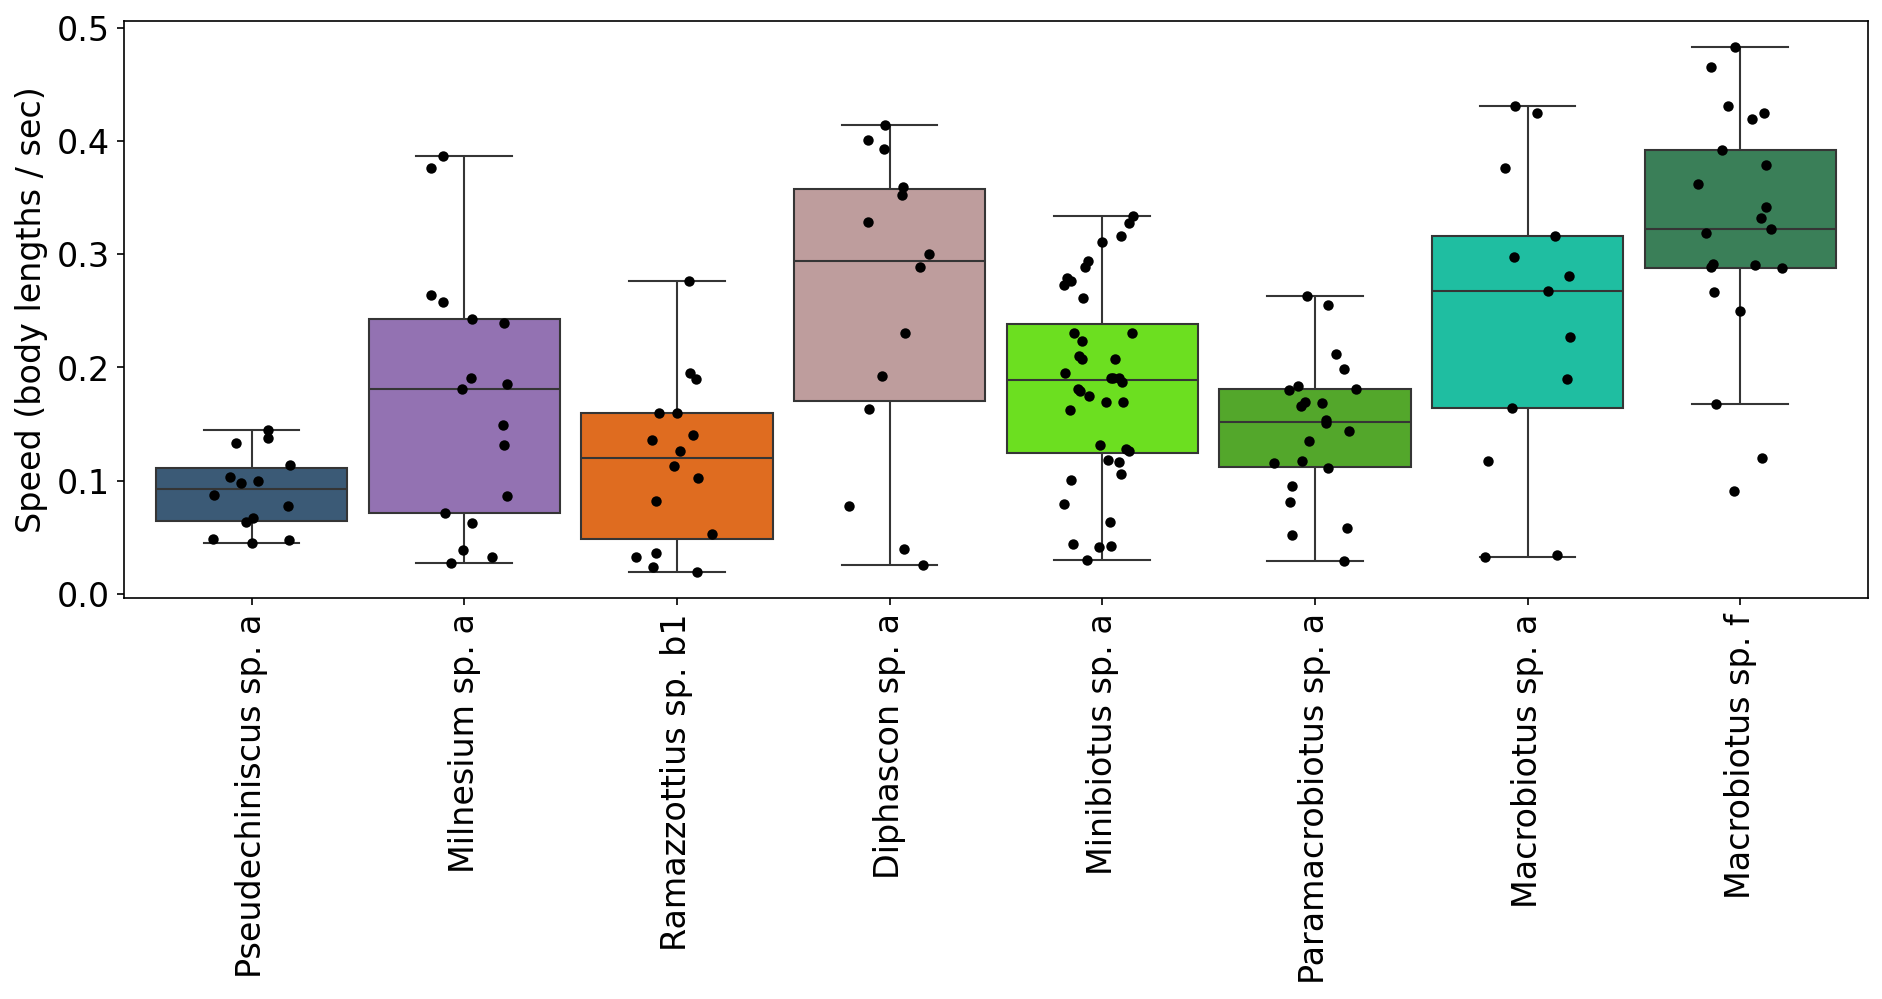

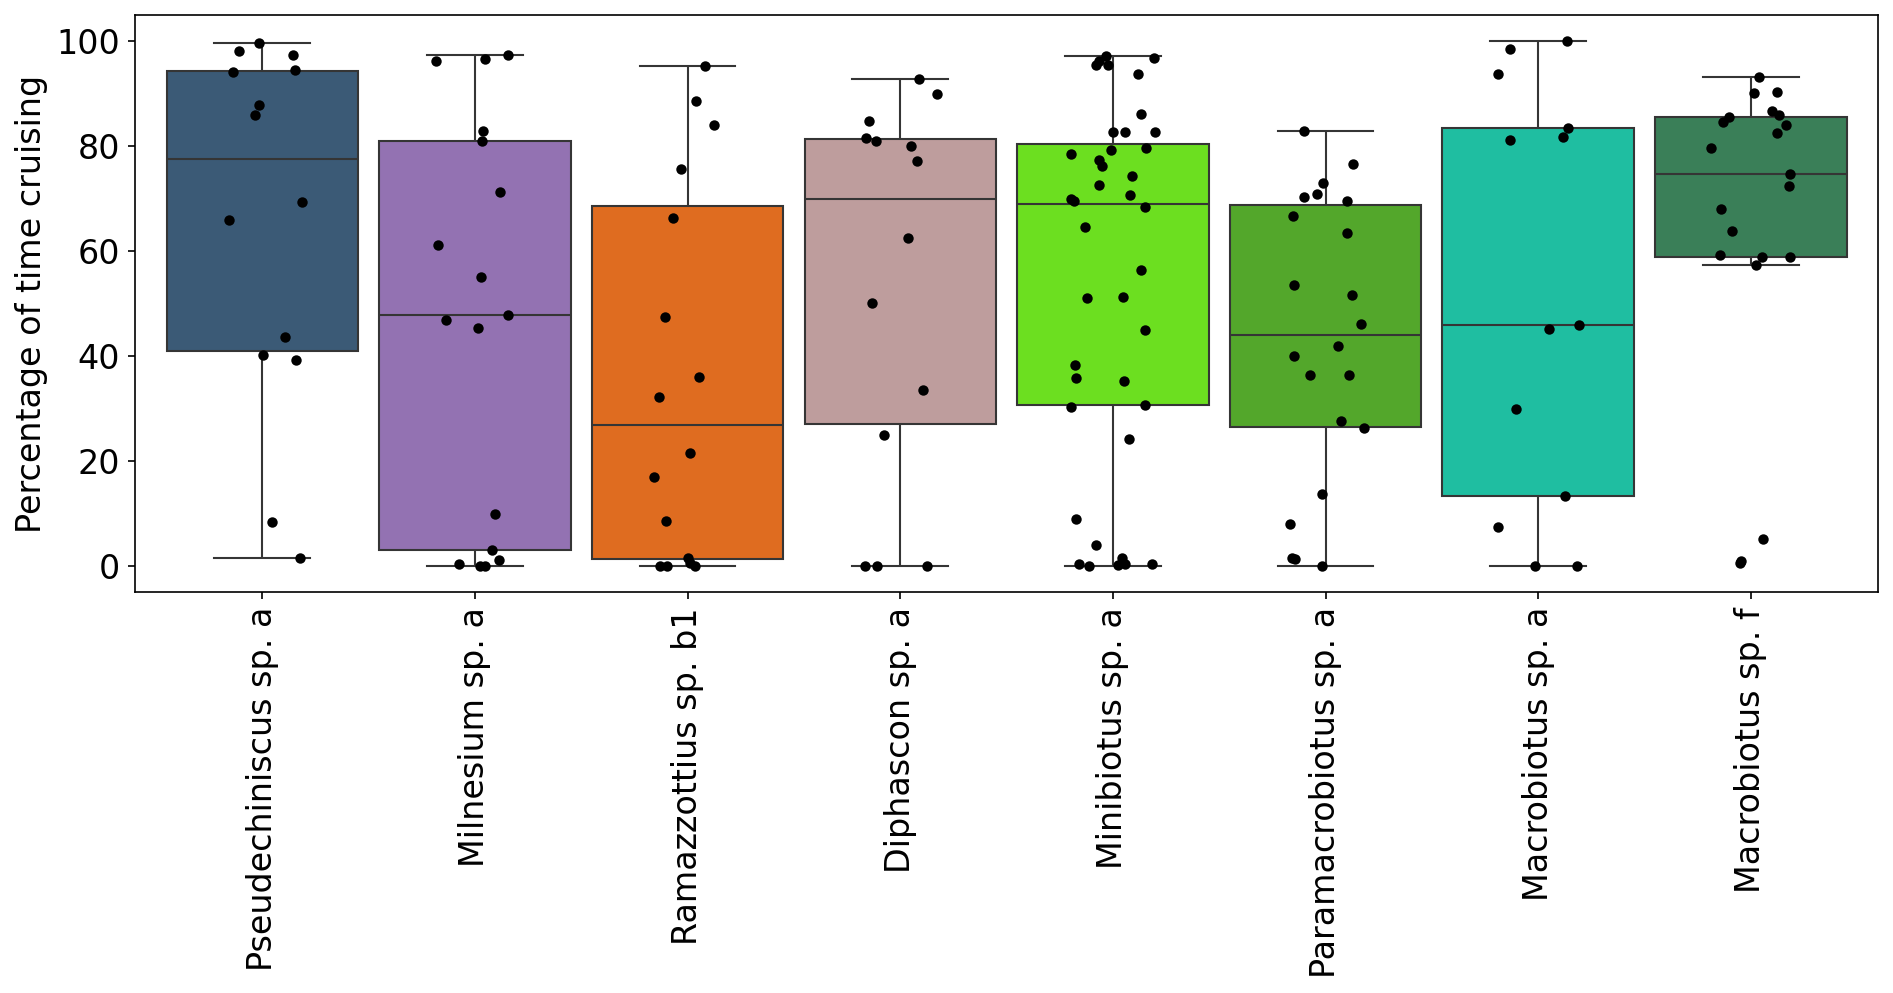

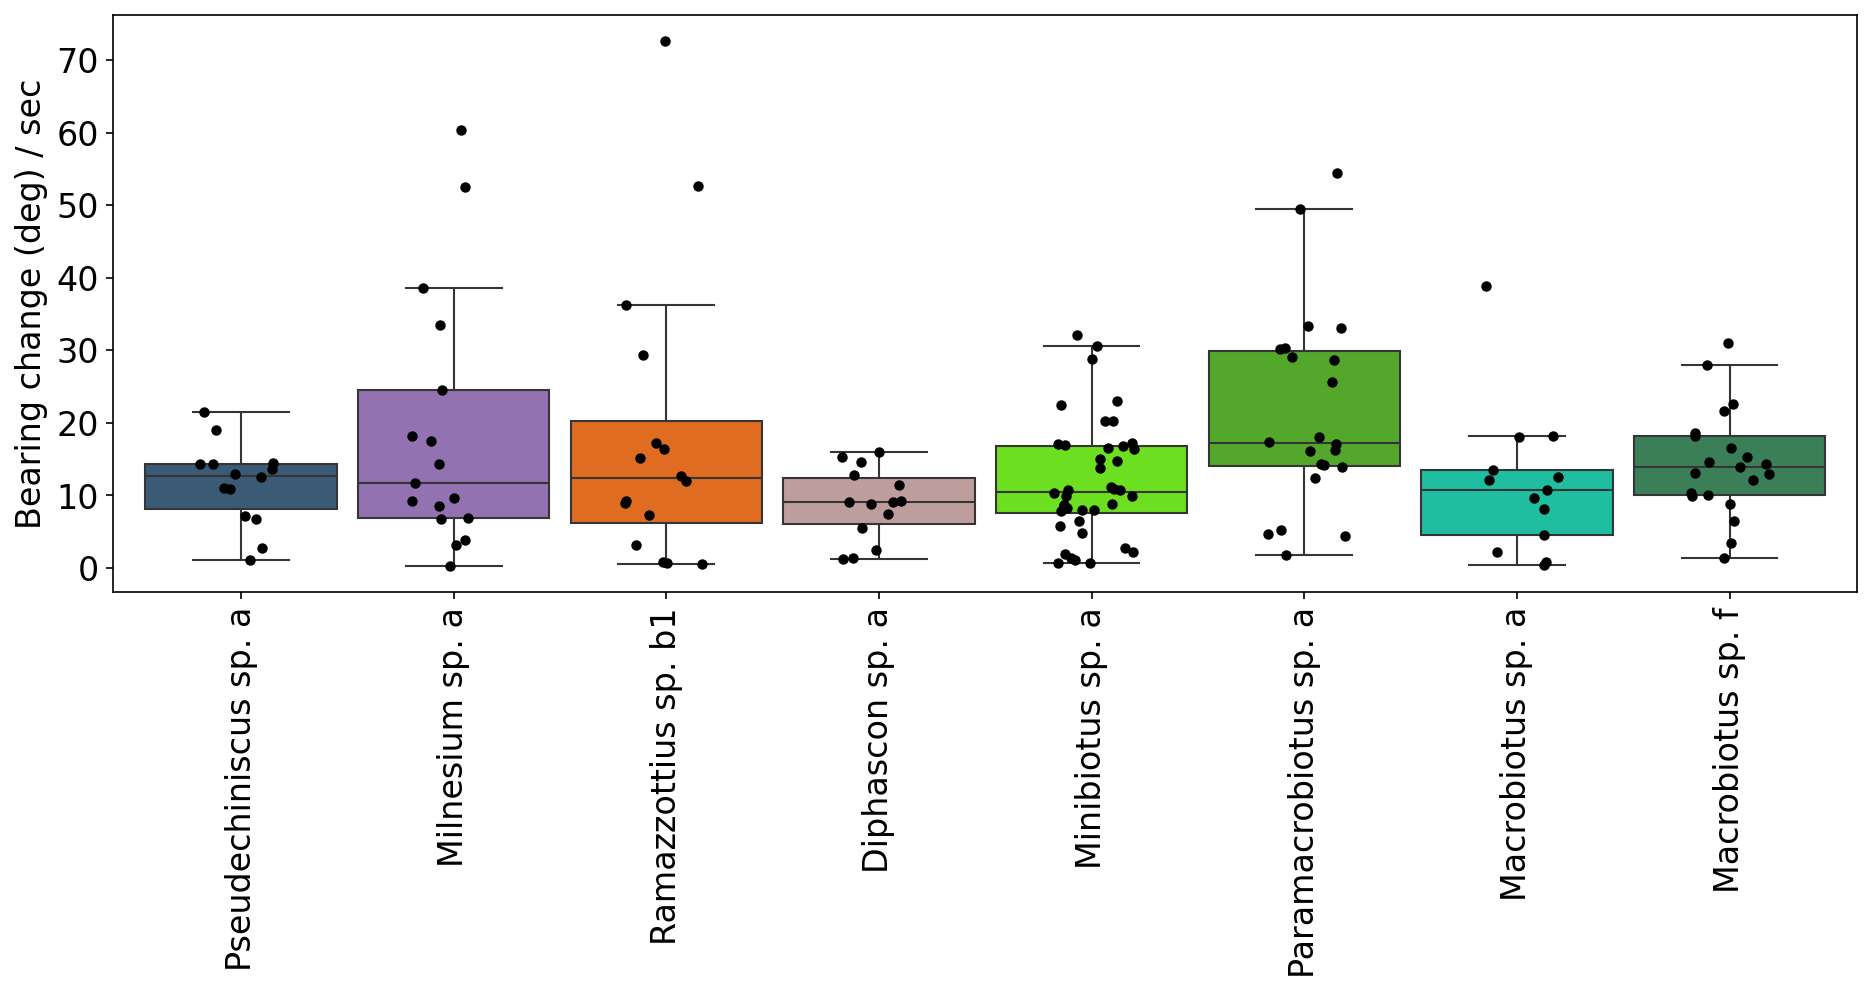

In [12]:
mover_choices = {'Speed (body lengths / sec)': 'bl_speed.txt',
                 'Percentage of time cruising': 'percent_cruising.txt',
                 'Bearing change (deg) / sec': 'bearing_change.txt'}

for col, statsdata in mover_choices.items():
    data = {otu: mover_df_dict[otu][col].values for otu in included_in_movers}
    compplot(data, col)
    plt.show()
    with open(statsdata, 'w') as o:
        for otu in data.keys():
            o.write(otu + '\t' + ','.join([str(x) for x in data[otu]]) + '\n')

# Figure 5C-F: locomotion in cruisers
Cruisers are individuals in the compared OTUs that have cruising (continuous locomotion) data.
 * `Speed (body lengths / sec cruising)` = similar to data for all movers, differences more clear
 * `Bearing change (deg) / sec cruising` = clear outliers, paramacrobiotus more delta bearing

In [13]:
# one table of cruisers: each row is an individual, with speed, bearing change, and body length
speed_col = 'Speed (body lengths / sec cruising)'
bearing_col = 'Bearing change (deg) / sec cruising'

cruiser_list = []
for otu in included_in_movers:
    otu_df = df_dict[otu]
    otu_df = otu_df[otu_df[speed_col].notna() & otu_df[bearing_col].notna()]
    cruiser_list.append(pd.DataFrame({'OTU': otu,
                                      'Individuals': otu_df['Identifier'].values,
                                      'Body Lengths': otu_df['Body Length (mm)'].values,
                                      'bl_speed': otu_df[speed_col].values,
                                      'bearing_change': otu_df[bearing_col].values,
                                      'color': otu_colors[otu],
                                      'marker': otu_markers[otu]}))
cruisers = pd.concat(cruiser_list, ignore_index=True)

# save the data in long form, one file per measurement
for tidycol, df_fname in [('bl_speed', 'speed_data_cruisers.xlsx'), ('bearing_change', 'bearing_data_cruisers.xlsx')]:
    cruisers[['OTU', tidycol, 'Individuals', 'Body Lengths', 'color', 'marker']].to_excel(df_fname)

print(len(cruisers), 'cruisers')
cruisers.head(5)

119 cruisers


,OTU,Individuals,Body Lengths,bl_speed,bearing_change,color,marker
0,Pseudechiniscus_a,20260516-s01-t02,0.137758,0.104320,15.880141,#315b80,diamond
1,Pseudechiniscus_a,20260516-s01-t03,0.160236,0.104317,12.209800,#315b80,diamond
2,Pseudechiniscus_a,20260516-s01-t04,0.166473,0.145151,10.927442,#315b80,diamond
3,Pseudechiniscus_a,20260516-s07-t04,0.185960,0.107870,11.916323,#315b80,diamond
4,Pseudechiniscus_a,20260604-s10-t05,0.155663,0.085072,16.026867,#315b80,diamond


In [14]:
# sampling summary for the cruisers in each OTU (Figure 5F)
print('OTU, Number, Number of dates sampled, Number of samples with otu')
sample_rows = []
for otu in included_in_movers:
    otu_ids = cruisers.loc[cruisers['OTU'] == otu, 'Individuals']
    n_dates = otu_ids.str[:8].nunique()
    n_samples = otu_ids.str[:12].nunique()
    print(otu, len(otu_ids), n_dates, n_samples)
    sample_rows.append([otu_original_to_revised[otu], len(otu_ids), n_dates, n_samples])
table_df = pd.DataFrame(sample_rows, columns=['OTU', 'N', '# Dates\nSampled', '# Samples\nwith OTU'])

OTU, Number, Number of dates sampled, Number of samples with otu
Pseudechiniscus_a 12 5 6
Milnesium_a 10 7 7
Ramazzottius_b1 9 8 9
Diphascon_a 11 4 5
Minibiotus_a 33 9 20
Paramacrobiotus_a 15 6 7
Macrobiotus_a 11 7 8
Macrobiotus_f 18 6 9


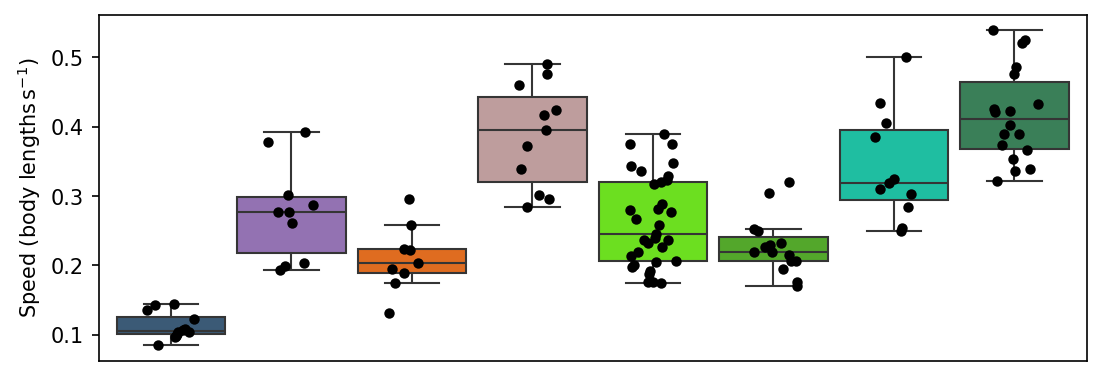

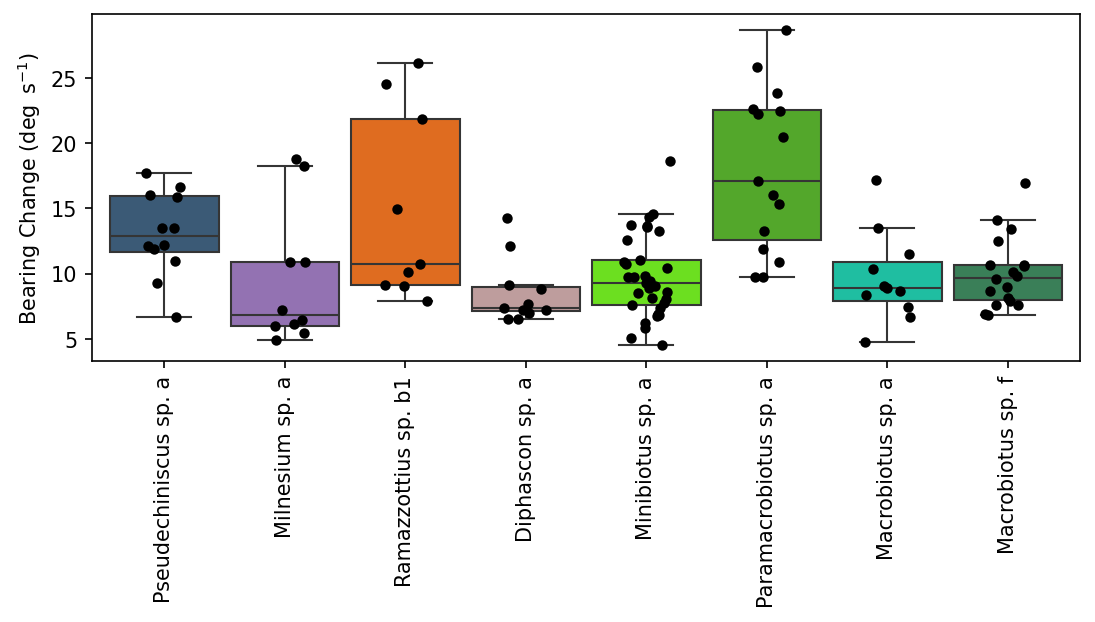

In [15]:
# box plots of cruising speed and bearing change (Figure 5C, 5E)
cruise_plots = [('bl_speed', r"Speed (body lengths$\,$s$^{-1}$)", 'fig5_speed_cruising.png', 'blspeed_cruising.txt'),
                ('bearing_change', r"Bearing Change (deg $\,$s$^{-1}$)", 'fig5_bearing_cruising.png', 'bearings_cruising.txt')]

for tidycol, ylabel, figname, statsdata in cruise_plots:
    data = {otu: cruisers.loc[cruisers['OTU'] == otu, tidycol].values for otu in included_in_movers}
    f, ax = compplot(data, tidycol, figsize=(8.5,3), markersize=5, labelsize=10)
    ax.set_ylabel(ylabel)
    if tidycol == 'bl_speed':
        ax.set_xticks([])
    with open(statsdata, 'w') as o:
        for otu in data.keys():
            o.write(otu + '\t' + ','.join([str(x) for x in data[otu]]) + '\n')
    plt.savefig(figname, bbox_inches='tight', transparent=True, dpi=300)
    plt.show()

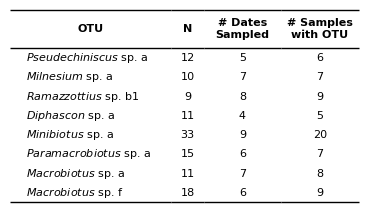

In [16]:
# table for sampling data and OTUs (Figure 5F)
def make_table(df, figsize=(5, 3), fontsize=10, col_widths=None, row_stripes=False):
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")

    def fmt(v, j):
        s = str(v)
        if j == 0: # italic genus only
            genus, _, rest = s.partition(" ")
            return f"$\\mathit{{{genus}}}$ {rest}"
        return s

    cell_text = [[fmt(v, j) for j, v in enumerate(row)] for row in df.values]

    tbl = ax.table(cellText=cell_text, colLabels=df.columns,
                   cellLoc="center", colWidths=col_widths, bbox=[0, 0, 1, 1])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(fontsize)

    # header height = number of lines in the tallest label
    header_lines = max(str(c).count("\n") + 1 for c in df.columns)

    n_rows = len(df)
    for (r, c), cell in tbl.get_celld().items():
        cell.set_facecolor("none")
        cell.set_edgecolor("none")
        if r == 0:
            cell.set_height(cell.get_height() * header_lines) # room for wrapped header
            cell.set_text_props(fontweight="bold", va="center")
            cell.visible_edges = "TB"
            cell.set_edgecolor("black")
            cell.set_linewidth(1.0)
        elif r == n_rows:
            cell.visible_edges = "B"
            cell.set_edgecolor("black")
            cell.set_linewidth(1.0)
        if row_stripes and r > 0 and r % 2 == 0:
            cell.set_facecolor("#f2f2f2")
        if c == 0 and r > 0: # left-align names, keep header centered
            cell._loc = "left"
            cell.get_text().set_ha("left")
    return fig, ax

fig, ax = make_table(table_df, figsize=(4.5, 2.5), fontsize=8,
                     col_widths=[0.5, 0.10, 0.24, 0.24])
fig.savefig("fig5_otu_table.png", bbox_inches="tight", pad_inches=0.05, dpi=300, transparent=True)
plt.show()

# Stats for cruising comparisons (Supplemental Tables 4 and 5)

In [17]:
# Kruskal-Wallis omnibus tests, with epsilon-squared effect size = H / (n - 1)
for tidycol in ['bl_speed', 'bearing_change']:
    groups = [cruisers.loc[cruisers['OTU'] == otu, tidycol].values for otu in included_in_movers]
    stat, p_val = stats.kruskal(*groups)
    n = len(cruisers)
    print(f"=== Kruskal-Wallis: {tidycol} ===")
    print(f"n = {n}, df = {len(groups) - 1}")
    print(f"H-statistic: {stat:.4f}")
    print(f"p-value: {p_val:.6e}")
    print(f"epsilon squared: {stat / (n - 1):.3f}\n")

=== Kruskal-Wallis: bl_speed ===
n = 119, df = 7
H-statistic: 79.7808
p-value: 1.526789e-14
epsilon squared: 0.676

=== Kruskal-Wallis: bearing_change ===
n = 119, df = 7
H-statistic: 34.6033
p-value: 1.327710e-05
epsilon squared: 0.293



In [18]:
# Dunn's post-hoc tests (Bonferroni) with Cliff's delta; saved as Excel tables with revised OTU names
dunn_setup = {
    'bl_speed': dict(more_text='Faster OTU', less_text='Slower OTU', more_num='n (faster)',
                     less_num='n (slower)', out='speed_dunn_bonferroni_results.xlsx'),
    'bearing_change': dict(more_text='Higher OTU', less_text='Lower OTU', more_num='n (higher)',
                           less_num='n (lower)', out='bearing_dunn_bonferroni_results.xlsx'),
}

def dunn_table(df, val, grp, more_text, less_text, more_num, less_num):
    # Dunn's test: unadjusted and Bonferroni-adjusted p-value matrices
    p_raw = sp.posthoc_dunn(df, val_col=val, group_col=grp, p_adjust=None)
    p_adj = sp.posthoc_dunn(df, val_col=val, group_col=grp, p_adjust="bonferroni")

    # Mean ranks (pooled) to orient each pair: higher mean rank first
    ranks = pd.Series(stats.rankdata(df[val]), index=df.index)
    mean_rank = ranks.groupby(df[grp]).mean()
    groups = {k: v[val].to_numpy() for k, v in df.groupby(grp)}

    rows = []
    for a, b in itertools.combinations(groups, 2):
        if mean_rank[a] < mean_rank[b]:
            a, b = b, a
        x, y = groups[a], groups[b]
        # scikit-posthocs returns p-values only, so recover |Z| from the two-sided p
        z = stats.norm.isf(p_raw.loc[a, b] / 2)
        # Cliff's delta from the Mann-Whitney U statistic (positive = a higher than b)
        U = stats.mannwhitneyu(x, y).statistic
        delta = 2 * U / (len(x) * len(y)) - 1
        rows.append({
            more_text: a,
            less_text: b,
            more_num: len(x),
            less_num: len(y),
            "Z": z,
            "p (unadjusted)": p_raw.loc[a, b],
            "p (Bonferroni)": p_adj.loc[a, b],
            "Cliff's delta": delta,
        })

    res = pd.DataFrame(rows).sort_values(["p (Bonferroni)", "p (unadjusted)"]).reset_index(drop=True)
    res["Significant (adj. p < 0.05)"] = np.where(res["p (Bonferroni)"] < 0.05, "Yes", "No")
    # Cliff's delta magnitude cutoffs (Romano et al.): negligible, small, medium, large
    res["Effect magnitude"] = pd.cut(res["Cliff's delta"].abs(),
                                     bins=[-0.001, 0.147, 0.33, 0.474, 1.001],
                                     labels=["negligible", "small", "medium", "large"]).astype(str)
    return res, p_adj

def save_dunn_table(res, p_adj, out):
    with pd.ExcelWriter(out, engine="openpyxl") as writer:
        res.to_excel(writer, sheet_name="Pairwise", index=False)
        p_adj.to_excel(writer, sheet_name="p_adj_matrix")

        ws = writer.sheets["Pairwise"]
        header_font = Font(name="Arial", bold=True)
        body_font = Font(name="Arial")
        sig_fill = PatternFill("solid", fgColor="E2EFDA")
        cols = list(res.columns)

        for c in ws[1]:
            c.font = header_font
            c.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        ws.freeze_panes = "A2"

        fmt = {"Z": "0.00", "p (unadjusted)": "0.00E+00",
               "p (Bonferroni)": "0.00E+00", "Cliff's delta": "0.00"}
        sig_col = cols.index("Significant (adj. p < 0.05)") + 1

        for row in ws.iter_rows(min_row=2):
            is_sig = row[sig_col - 1].value == "Yes"
            for c in row:
                c.font = Font(name="Arial", bold=is_sig)
                if is_sig:
                    c.fill = sig_fill
                name = cols[c.column - 1]
                if name in fmt:
                    c.number_format = fmt[name]

        for i, name in enumerate(cols, start=1):
            width = max(len(str(name)), *(len(str(v)) for v in res[name])) + 2
            ws.column_dimensions[get_column_letter(i)].width = min(width, 28)

        # second sheet formatting
        ws2 = writer.sheets["p_adj_matrix"]
        for row in ws2.iter_rows():
            for c in row:
                c.font = body_font
                if isinstance(c.value, float):
                    c.number_format = "0.00E+00"
        ws2.column_dimensions["A"].width = 20
        for i in range(2, ws2.max_column + 1):
            ws2.column_dimensions[get_column_letter(i)].width = 18
    print('Saved results to ' + out)

for tidycol, setup in dunn_setup.items():
    setup = dict(setup)
    out = setup.pop('out')
    res, p_adj = dunn_table(cruisers, tidycol, 'OTU', **setup)

    # revised OTU names for the saved tables
    for c in [setup['more_text'], setup['less_text']]:
        res[c] = res[c].map(otu_original_to_revised)
    p_adj = p_adj.rename(index=otu_original_to_revised, columns=otu_original_to_revised)

    print(f"\n=== Dunn's test, {tidycol}: significant pairs (Bonferroni p < 0.05) ===")
    sig = res[res["Significant (adj. p < 0.05)"] == "Yes"]
    print(sig[[setup['more_text'], setup['less_text'], "p (Bonferroni)", "Cliff's delta"]].to_string(index=False))
    save_dunn_table(res, p_adj, out)


=== Dunn's test, bl_speed: significant pairs (Bonferroni p < 0.05) ===
       Faster OTU            Slower OTU  p (Bonferroni)  Cliff's delta
Macrobiotus sp. f Pseudechiniscus sp. a    5.262076e-12       1.000000
  Diphascon sp. a Pseudechiniscus sp. a    4.480188e-08       1.000000
Macrobiotus sp. a Pseudechiniscus sp. a    5.376613e-06       1.000000
Macrobiotus sp. f Paramacrobiotus sp. a    1.774501e-05       1.000000
Macrobiotus sp. f   Ramazzottius sp. b1    4.511286e-05       1.000000
Macrobiotus sp. f      Minibiotus sp. a    9.304049e-05       0.898990
 Minibiotus sp. a Pseudechiniscus sp. a    1.198101e-03       1.000000
  Diphascon sp. a   Ramazzottius sp. b1    3.166962e-03       0.979798
  Diphascon sp. a Paramacrobiotus sp. a    3.670734e-03       0.927273
  Milnesium sp. a Pseudechiniscus sp. a    1.131168e-02       1.000000
  Diphascon sp. a      Minibiotus sp. a    2.984834e-02       0.785124
Saved results to speed_dunn_bonferroni_results.xlsx

=== Dunn's test, bearin

# Body length vs. speed (Figure 5D)

n = 119
slope = 0.1452  (95% CI -0.0390 to 0.3294)
intercept = 0.2459
r = 0.143,  R^2 = 0.020,  Cohen's f^2 = 0.021
p (slope) = 0.1211


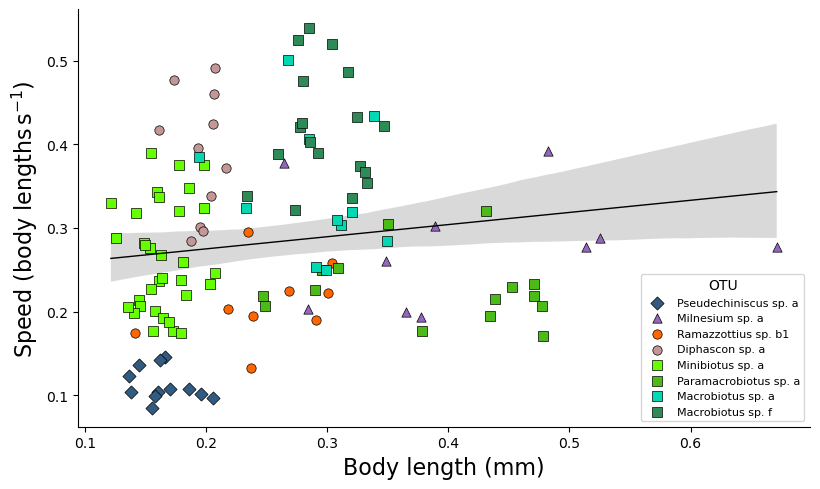

In [19]:
x_col, y_col = "Body Lengths", "bl_speed"

# map the text labels in the 'marker' column to matplotlib marker codes
marker_map = {"circle": "o", "square": "s", "diamond": "D", "triangle": "^"}

# linear regression across all cruisers
res = stats.linregress(cruisers[x_col], cruisers[y_col])
n = len(cruisers)
r2 = res.rvalue ** 2
f2 = r2 / (1 - r2) # Cohen's f^2
t_crit = stats.t.ppf(0.975, n - 2)
slope_ci = (res.slope - t_crit * res.stderr, res.slope + t_crit * res.stderr)

print(f"n = {n}")
print(f"slope = {res.slope:.4f}  (95% CI {slope_ci[0]:.4f} to {slope_ci[1]:.4f})")
print(f"intercept = {res.intercept:.4f}")
print(f"r = {res.rvalue:.3f},  R^2 = {r2:.3f},  Cohen's f^2 = {f2:.3f}")
print(f"p (slope) = {res.pvalue:.4f}")

# points: one scatter call per OTU so color and marker both follow the columns
fig, ax = plt.subplots(figsize=(8.3, 5))
for otu in included_in_movers:
    d = cruisers[cruisers["OTU"] == otu]
    ax.scatter(d[x_col], d[y_col],
               c=d["color"].iloc[0],
               marker=marker_map[d["marker"].iloc[0]],
               s=45, edgecolor="black", linewidth=0.5,
               label=otu_original_to_revised[otu], zorder=2)

# regression line + 95% CI band on top (points already drawn above)
sns.regplot(data=cruisers, x=x_col, y=y_col, scatter=False, ci=95, ax=ax,
            line_kws={"color": "black", "linewidth": 1, "zorder": 3},
            color="darkgray")

ax.set_xlabel("Body length (mm)", fontsize=16)
ax.set_ylabel(r"Speed (body lengths$\,$s$^{-1}$)", fontsize=16)
ax.legend(title="OTU", frameon=True, fontsize=8, loc="lower right")
sns.despine()
fig.tight_layout()
fig.savefig("fig5_speed_vs_bodylength.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

# Body length vs. speed vs. OTU: analysis of covariance

In [20]:
df = cruisers.rename(columns={"Body Lengths": "body_len"})

# Main model: body length + OTU as a factor
m = smf.ols("bl_speed ~ body_len + C(OTU)", data=df).fit()
print(m.summary())

# Type II ANOVA table with partial eta^2 and Cohen's f^2
aov = sm.stats.anova_lm(m, typ=2)
ss_res = aov.loc["Residual", "sum_sq"]
aov["partial_eta2"] = aov["sum_sq"] / (aov["sum_sq"] + ss_res)
aov["cohens_f2"] = aov["partial_eta2"] / (1 - aov["partial_eta2"])
aov.loc["Residual", ["partial_eta2", "cohens_f2"]] = np.nan
print(aov)

# Is the slope the same in every OTU? (interaction)
m_int = smf.ols("bl_speed ~ body_len * C(OTU)", data=df).fit()
print("\nSlope-homogeneity test (body_len x OTU):")
print(sm.stats.anova_lm(m, m_int))

# Body-length slope: classical vs heteroscedasticity-robust
m_hc3 = smf.ols("bl_speed ~ body_len + C(OTU)", data=df).fit(cov_type="HC3")
for label, mod in [("OLS", m), ("HC3 robust", m_hc3)]:
    lo, hi = mod.conf_int().loc["body_len"]
    print(f"{label:11s} slope = {mod.params['body_len']:.4f} "
          f"(95% CI {lo:.4f} to {hi:.4f}), p = {mod.pvalues['body_len']:.3f}")

# Diagnostics
print("\nShapiro-Wilk on residuals:", stats.shapiro(m.resid))
bp = sm.stats.diagnostic.het_breuschpagan(m.resid, m.model.exog)
print(f"Breusch-Pagan: LM = {bp[0]:.2f}, p = {bp[1]:.3f}")
print(f"R^2 = {m.rsquared:.3f}, adj. R^2 = {m.rsquared_adj:.3f}")

                            OLS Regression Results                            
Dep. Variable:               bl_speed   R-squared:                       0.692
Model:                            OLS   Adj. R-squared:                  0.670
Method:                 Least Squares   F-statistic:                     30.91
Date:                Fri, 27 Nov 2026   Prob (F-statistic):           7.64e-25
Time:                        19:53:45   Log-Likelihood:                 167.50
No. Observations:                 119   AIC:                            -317.0
Df Residuals:                     110   BIC:                            -292.0
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

In [21]:
# Within-OTU regressions of speed and bearing change on body length
for tidycol in ['bl_speed', 'bearing_change']:
    print(f"\n{tidycol} vs. body length, within each OTU")
    for otu in included_in_movers:
        d = cruisers[cruisers['OTU'] == otu]
        lr = stats.linregress(d['Body Lengths'], d[tidycol])
        print(f"{otu_original_to_revised[otu]:24s} n = {len(d):3d}  slope = {lr.slope:9.3f}  p = {lr.pvalue:.3f}")


bl_speed vs. body length, within each OTU
Pseudechiniscus sp. a    n =  12  slope =    -0.254  p = 0.368
Milnesium sp. a          n =  10  slope =     0.078  p = 0.699
Ramazzottius sp. b1      n =   9  slope =     0.320  p = 0.364
Diphascon sp. a          n =  11  slope =    -0.247  p = 0.876
Minibiotus sp. a         n =  33  slope =     0.245  p = 0.654
Paramacrobiotus sp. a    n =  15  slope =    -0.070  p = 0.596
Macrobiotus sp. a        n =  11  slope =    -0.429  p = 0.464
Macrobiotus sp. f        n =  18  slope =    -0.050  p = 0.931

bearing_change vs. body length, within each OTU
Pseudechiniscus sp. a    n =  12  slope =    47.310  p = 0.310
Milnesium sp. a          n =  10  slope =   -12.599  p = 0.394
Ramazzottius sp. b1      n =   9  slope =   -16.621  p = 0.765
Diphascon sp. a          n =  11  slope =   -45.798  p = 0.377
Minibiotus sp. a         n =  33  slope =   -16.789  p = 0.532
Paramacrobiotus sp. a    n =  15  slope =    13.453  p = 0.499
Macrobiotus sp. a        n